# Finite-intercept experiment and best ones

This new study enables an **unpenalized intercept in both stages**. The preferred
class uses logistic loss, the identical optimizer and iteration budget, and the
same fitted coefficient vectors for auxiliary and posterior-input construction.
The permitted alternative uses exact weighted least squares **with an intercept**
for the auxiliary fit, followed by finite-iteration logistic with an intercept.
No L1 or L2 fitting penalties are used anywhere in this sweep.

Optimizers: monotone FISTA, deterministic full-batch gradient descent, and L-BFGS-B.
Budgets: 1, 3, 10, 30, 100 updates. Each fit starts with zero slopes and the weighted
intercept-only logistic MLE. The constant column is $1/\sqrt n$, so its norm matches
the whitened feature columns; its fitted coefficient is converted back to an
ordinary intercept. This preconditioning is declared because early stopping depends
on parameterization. FISTA/GD use the reciprocal exact global logistic curvature
bound; L-BFGS uses memory 10, at most 20 line-search steps, and zero convergence
tolerances. Actual iteration counts and intercept score residuals are recorded.

Minimum segment sizes are $\Delta=1,2,5$. Rho updates are 1, 3, 10, 20, 30, with
start $I_2$, damping 0.25 and eigenvalue clipping to $[10^{-4},100]$. LS also includes
the direct approximate moment fit. Additional starts $0.1I_2$ and $10I_2$ are tested
at Delta=1, fitting budgets 10/30, all three optimizers, and 3/10/30 rho updates.
The design contains **531 primary posterior comparisons** when all fits/states
are numerically evaluable. Failed settings are recorded, not silently discarded.

Data/preprocessing remain 1,692 age-sorted observations, 110 mean-imputed centered
predictors, covariance whitening with $10^{-6}I$ and division by $\sqrt n$.
Prior odds for zero/one change remain one-half each; conditional location is uniform
over admissible distinct-age splits. The pilot segmentation is estimated from the
auxiliary loss and held fixed during rho updates. Posterior locations are not
restricted to the pilot. The logistic posterior uses the existing intercept-aware,
global-prevalence-calibrated observation model. This is an **empirical-Bayes heuristic
extension**, not the original zero-offset theorem. The limiting state equations
are not exact finite-iteration theory; adjusted-score means, intercept scores, and
moment residuals are therefore included as diagnostics.

Primary states: 256 Sobol draws/seed 42, at most 60 evaluations, 160-node quadrature.
The top ten shapes in each auxiliary class, plus nearby shape/probability trade-offs,
receive checks with 512 draws/seed 42 and 1,024 draws/seed 123, at most 100 evaluations.
Rank by mean TV to the full archived age distribution; no P(1)>0.5 eligibility
threshold. Outcome-guided ranking is exploratory and the numerical ranges are not
confidence intervals. Existing no-intercept results remain unchanged.


In [1]:
"""Matched-intercept early-stopping sweep, with explicit model/provenance."""
from tools.myocardial_exploration import *
from tools.myocardial_finite_iteration_exploration import reference_distribution
from tools.myocardial_intercept_exploration import offset_rho_path
from WERM.myocardial_intercept import (fit_with_intercept,squared_intercept_state,
    logistic_intercept_state,intercept_loglikelihood)
from WERM.myocardial_finite_intercept import finite_intercept_fit

METHODS=('fista','lbfgs','gd')
FIT_STEPS=(1,3,10,30,100)
MIN_SEGMENTS=(1,2,5)
RHO_STEPS=(1,3,10,20,30)


def experiment_root():
    files=['tools/myocardial_finite_intercept_sweep.py','WERM/myocardial_finite_intercept.py',
           'WERM/myocardial_intercept.py','WERM/signal_strength.py','WERM/myocardial_numerics.py',
           'WERM/proximal.py','results/myocardial_raw_uci579.csv']
    specification=dict(methods=METHODS,fit_steps=FIT_STEPS,minimum_segments=MIN_SEGMENTS,rho_steps=RHO_STEPS,
        intercept=True,penalty='none',count_prior=[.5,.5],intercept_column='1/sqrt(n)',
        coefficient_start='zero slopes, weighted intercept-only logistic MLE',
        response_model='prevalence-calibrated intercept model; finite-fit state equations are heuristic',
        files={p:hashlib.sha256(Path(p).read_bytes()).hexdigest() for p in files})
    digest=hashlib.sha256(json.dumps(specification,sort_keys=True).encode()).hexdigest()[:12]
    root=Path('results')/('myocardial_finite_intercept_'+digest);root.mkdir(exist_ok=True)
    (root/'specification.json').write_text(json.dumps(specification,indent=2));return root


def setting_for(delta,y,locations):
    eta,prior,phi=configuration_prior(len(y),locations[(locations>=delta)&(locations<=len(y)-delta)])
    return dict(delta_min=delta,eta=eta,prior=prior,phi=phi,rate=float(y.mean()))


def fit_task(delta,name,X,y,setting,root):
    path=root/f'fit_d{delta}_{name}.pkl'
    if path.exists():return pickle.load(path.open('rb'))
    try:
        if name=='least_squares':
            fit=fit_with_intercept(X,y,setting['phi'],'none',0.,loss='squared')
            fit.update(method='least_squares',budget=0,fit_intercept=True)
        else:
            method,budget=name.split('_');fit=finite_intercept_fit(X,y,setting['phi'],method,int(budget))
        fit['adjusted_score_mean']=fit['V'].mean(axis=0)
        result=dict(name=name,delta_min=delta,fit=fit)
    except Exception as error:result=dict(name=name,delta_min=delta,error=repr(error),traceback=traceback.format_exc())
    atomic_save(path,result);return result


def rho_task(fit_rec,setting,X,y,initial_scale,root):
    name=fit_rec['name'];delta=setting['delta_min'];prefix=f'd{delta}_{name}_start{initial_scale:g}'
    path=root/('rho_'+prefix+'.pkl')
    if path.exists():return pickle.load(path.open('rb'))
    try:
        fit=fit_rec['fit'];loss='squared' if name=='least_squares' else 'logistic'
        e,psi=pilot(fit['theta'],y,setting['eta'],loss);S=fit['V'].T@fit['V']/len(y)
        rho=initial_scale*np.eye(2);records=[]
        updates=RHO_STEPS if initial_scale==1 else (3,10,30)
        def state_at(matrix,power=7,budget=40):
            return squared_intercept_state(matrix,setting['phi'],psi,len(y)/X.shape[1],setting['rate']) if loss=='squared' else logistic_intercept_state(
                matrix,setting['phi'],psi,len(y)/X.shape[1],setting['rate'],sample_power=power,max_nfev=budget)
        for it in range(1,max(updates)+1):
            state=state_at(rho);inv=np.linalg.pinv(state['lambda'],rcond=1e-6)
            rho=project_covariance(.75*rho+.25*project_covariance(inv.T@(S-state['kappa'])@inv))
            if it in updates:
                check=state_at(rho,8,60);residual=float(np.linalg.norm(check['lambda'].T@rho@check['lambda']+check['kappa']-S))
                records.append(dict(label=prefix+f'_rho{it}',rho=rho.copy(),rho_updates=it,
                    auxiliary=name,initial_scale=initial_scale,pilot=e,loss=loss,delta_min=delta,
                    moment_residual=residual,relative_moment_residual=residual/max(np.linalg.norm(S),1e-15),
                    auxiliary_adjusted_mean_norm=float(np.linalg.norm(fit['adjusted_score_mean']))))
        if loss=='squared' and initial_scale==1:
            direct=offset_rho_path(S,setting['phi'],psi,len(y)/X.shape[1],setting['rate'],'squared')[-1]
            records.append(dict(label=prefix+'_rho_direct',rho=direct['rho'],rho_updates=-1,
                auxiliary=name,initial_scale=1,pilot=e,loss=loss,delta_min=delta,
                moment_residual=direct['moment_residual'],relative_moment_residual=direct['moment_residual']/max(np.linalg.norm(S),1e-15),
                auxiliary_adjusted_mean_norm=float(np.linalg.norm(fit['adjusted_score_mean']))))
        result=dict(records=records)
    except Exception as error:result=dict(error=repr(error),case=prefix,traceback=traceback.format_exc())
    atomic_save(path,result);print('Rho trajectory finished:',prefix,flush=True);return result


def state_task(rec,setting,n,p,root,power,seed,budget):
    tag=f'q{power}_seed{seed}_b{budget}';path=root/(rec['label']+'_'+tag+'_states.pkl')
    if path.exists():return pickle.load(path.open('rb'))
    partial=path.with_name(path.stem+'_partial.pkl')
    states=pickle.load(partial.open('rb')) if partial.exists() else []
    try:
        for e in setting['eta'][len(states):]:
            psi=np.zeros(n,int) if e<0 else (np.arange(n)>=e).astype(int)
            states.append(logistic_intercept_state(rec['rho'],setting['phi'],psi,n/p,setting['rate'],
                sample_power=power,max_nfev=budget,seed=seed))
            if len(states)%8==0:atomic_save(partial,states)
        result=dict(states=states)
    except Exception as error:result=dict(error=repr(error),case=rec['label'],tag=tag,traceback=traceback.format_exc())
    atomic_save(path,result);print('Posterior states:',rec['label'],tag,flush=True);return result


def score_task(rec,bundle,setting,fit_rec,X,y,ages,reference,root,tag):
    name=fit_rec['name'];label=rec['label']+'__'+name+'__'+tag;path=root/(label+'.pkl')
    if path.exists():return pickle.load(path.open('rb'))
    try:
        fit=fit_rec['fit'];ll=[]
        for e,state in zip(setting['eta'],bundle['states']):
            psi=np.zeros(len(y),int) if e<0 else (np.arange(len(y))>=e).astype(int)
            ll.append(intercept_loglikelihood(fit['V'],y,rec['rho'],state,psi))
        ll=np.asarray(ll);joint=ll+np.log(setting['prior']);probs=np.exp(joint-logsumexp(joint))
        curve=np.exp(ll[1:]-logsumexp(ll[1:]));a=ages[setting['eta'][1:]];mapping=dict(zip(a,curve))
        tv=.5*sum(abs(reference[k]-mapping.get(k,0.)) for k in reference)
        assert np.isfinite(ll).all() and np.isfinite(curve).all()
        result=dict(label=label,case=rec['label'],posterior_fit=name,auxiliary=rec['auxiliary'],
            group='LS_auxiliary' if rec['auxiliary']=='least_squares' else 'matched_logistic',
            method=fit['method'],fit_budget=fit['budget'],intercept=True,explicit_penalty=0.,
            Delta=rec['delta_min'],rho_updates=rec['rho_updates'],initial_scale=rec['initial_scale'],
            pilot_index=rec['pilot'],pilot_age=float(ages[rec['pilot']]) if rec['pilot']>=0 else np.nan,
            tag=tag,P_1=float(probs[1:].sum()),conditional=curve,ages=a,
            mass_above55=float(curve[a>55].sum()),peak_age=float(a[np.argmax(curve)]),
            TV_to_reference=tv,max_location_probability=float(curve.max()),
            moment_residual=rec['moment_residual'],relative_moment_residual=rec['relative_moment_residual'],
            posterior_adjusted_mean_norm=float(np.linalg.norm(fit['adjusted_score_mean'])),
            auxiliary_adjusted_mean_norm=rec['auxiliary_adjusted_mean_norm'],
            intercept_score_max=max(abs(c['intercept_score']) for c in fit['checks']),
            fit_kkt_max=max(c['kkt'] for c in fit['checks']),
            actual_iterations_max=max(c['iterations'] for c in fit['checks']),
            FP_residual_max=max(s['training_residual'] for s in bundle['states']))
    except Exception as error:result=dict(error=repr(error),case=rec['label'],posterior_fit=name,tag=tag,traceback=traceback.format_exc())
    atomic_save(path,result);return result


def scalar_table(rows):
    return pd.DataFrame([{k:v for k,v in r.items() if k not in ('conditional','ages')} for r in rows if 'error' not in r])


def run_sweep(smoke=False):
    X,y,ages,locations=load_data();reference=reference_distribution();root=experiment_root()
    print('Finite-intercept experiment directory:',root,flush=True)
    settings={d:setting_for(d,y,locations) for d in MIN_SEGMENTS}
    names=[f'{method}_{budget}' for method in METHODS for budget in FIT_STEPS]
    with parallel_config(backend='loky',inner_max_num_threads=1):
        fitted=Parallel(n_jobs=3 if smoke else 36)(delayed(fit_task)(d,name,X,y,settings[d],root)
                    for d in ((1,) if smoke else MIN_SEGMENTS) for name in names+['least_squares'])
    errors=[r for r in fitted if 'error' in r];fits={(r['delta_min'],r['name']):r for r in fitted if 'error' not in r}
    if smoke:
        assert not errors,errors
        for r in fitted:
            fit=r['fit'];assert np.isfinite(fit['V']).all()
            if r['name']!='least_squares':assert max(c['iterations'] for c in fit['checks'])<=fit['budget']
        e=settings[1]['eta'][len(settings[1]['eta'])//2];psi=(np.arange(len(y))>=e).astype(int)
        state=logistic_intercept_state(np.eye(2),settings[1]['phi'],psi,len(y)/X.shape[1],settings[1]['rate'],sample_power=7,max_nfev=40)
        ll=intercept_loglikelihood(fits[(1,'fista_10')]['fit']['V'],y,np.eye(2),state,psi)
        assert np.isfinite(ll);print('Real-data smoke passed: all 15 logistic fits, LS, and intercept posterior.',flush=True);return root
    rho_jobs=[(r,1.) for r in fits.values()]
    rho_jobs += [(fits[(1,f'{method}_{budget}')],scale) for method in METHODS for budget in (10,30)
                 for scale in (.1,10.) if (1,f'{method}_{budget}') in fits]
    with parallel_config(backend='loky',inner_max_num_threads=1):
        paths=Parallel(n_jobs=36)(delayed(rho_task)(r,settings[r['delta_min']],X,y,scale,root) for r,scale in rho_jobs)
        records=[r for path in paths if 'error' not in path for r in path['records']]
        errors.extend(p for p in paths if 'error' in p)
        bundles=Parallel(n_jobs=36)(delayed(state_task)(r,settings[r['delta_min']],len(y),X.shape[1],root,8,42,60) for r in records)
        errors.extend(b for b in bundles if 'error' in b)
        jobs=[(r,bundle,fits[(r['delta_min'],name)]) for r,bundle in zip(records,bundles) if 'error' not in bundle
              for name in (names if r['auxiliary']=='least_squares' else [r['auxiliary']]) if (r['delta_min'],name) in fits]
        scores=Parallel(n_jobs=36)(delayed(score_task)(r,b,settings[r['delta_min']],fit,X,y,ages,reference,root,'primary') for r,b,fit in jobs)
    errors.extend(r for r in scores if 'error' in r);summary=scalar_table(scores)
    summary.to_csv(root/'summary.csv',index=False)
    selected_parts=[summary.sort_values('TV_to_reference').head(10)]
    for group,data in summary.groupby('group'):
        selected_parts.extend([data.sort_values('TV_to_reference').head(10),
            data[data.TV_to_reference<=data.TV_to_reference.min()+.1].sort_values('P_1',ascending=False).head(2)])
    selected=pd.concat(selected_parts).drop_duplicates('label');selected.to_csv(root/'selected_for_validation.csv',index=False)
    by_case={r['label']:r for r in records}
    validation_jobs=[(by_case[c],power,seed) for c in selected.case.unique() for power,seed in ((9,42),(10,123))]
    with parallel_config(backend='loky',inner_max_num_threads=1):
        refined=Parallel(n_jobs=36)(delayed(state_task)(r,settings[r['delta_min']],len(y),X.shape[1],root,power,seed,100)
                                  for r,power,seed in validation_jobs)
        checks=Parallel(n_jobs=36)(delayed(score_task)(r,b,settings[r['delta_min']],fits[(r['delta_min'],row.posterior_fit)],
            X,y,ages,reference,root,f'q{power}_seed{seed}') for (r,power,seed),b in zip(validation_jobs,refined) if 'error' not in b
            for row in selected[selected.case==r['label']].itertuples())
    errors.extend(b for b in refined if 'error' in b);errors.extend(c for c in checks if 'error' in c)
    validation=scalar_table(checks);validation.to_csv(root/'validation.csv',index=False)
    rows=[]
    for (case,posterior),data in validation.groupby(['case','posterior_fit']):
        if len(data)!=2:continue
        original=data.iloc[0].to_dict();curves=[pickle.load((root/(r.label+'.pkl')).open('rb'))['conditional'] for r in data.itertuples()]
        original.update(P1_min=data.P_1.min(),P1_max=data.P_1.max(),mean_TV=data.TV_to_reference.mean(),max_TV=data.TV_to_reference.max(),
            numerical_curve_TV=float(.5*np.abs(curves[0]-curves[1]).sum()),mass_above55_min=data.mass_above55.min(),
            peak_min=data.peak_age.min(),peak_max=data.peak_age.max())
        rows.append(original)
    ranked=pd.DataFrame(rows).sort_values(['mean_TV','max_TV']);ranked.to_csv(root/'ranked.csv',index=False)
    ranked.head(10).to_csv(root/'top_ten.csv',index=False)
    ranked[ranked.group=='matched_logistic'].head(10).to_csv(root/'top_ten_matched_logistic.csv',index=False)
    (root/'errors.json').write_text(json.dumps(errors,indent=2,default=str))
    print('FINITE INTERCEPT SWEEP COMPLETE:',len(summary),'primary comparisons;',len(validation),'checks;',len(errors),'recorded failures.',flush=True)
    print(ranked[['group','method','fit_budget','Delta','rho_updates','initial_scale','P1_min','P1_max','mean_TV']].head(10).to_string(index=False),flush=True)
    return root




/scratch/ga442/gab-code-env/papers/WeightedERM-reference/.venv-phase1/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
root=run_sweep()
summary=pd.read_csv(root/'summary.csv')
ranked=pd.read_csv(root/'ranked.csv')
failures=json.loads((root/'errors.json').read_text())
print('Primary comparisons:',len(summary),'recorded failures:',len(failures))
if failures:display(pd.DataFrame(failures))
columns=['group','method','fit_budget','Delta','rho_updates','initial_scale','P1_min','P1_max',
         'mean_TV','numerical_curve_TV','mass_above55_min','peak_min','peak_max',
         'relative_moment_residual','posterior_adjusted_mean_norm','intercept_score_max']
print('Top ten overall');display(ranked.head(10)[columns])
print('Top ten matched logistic/logistic');display(ranked[ranked.group=='matched_logistic'].head(10)[columns])


Finite-intercept experiment directory: results/myocardial_finite_intercept_e56e1d9d6bdb


Rho trajectory finished: d1_least_squares_start1
Rho trajectory finished: d2_least_squares_start1


Rho trajectory finished: d2_lbfgs_1_start1


Rho trajectory finished: d2_gd_3_start1


Rho trajectory finished: d2_gd_10_start1


Rho trajectory finished: d2_fista_30_start1


... (343 outputs left out)

Primary comparisons: 531 recorded failures: 0
Top ten overall


,group,method,fit_budget,Delta,rho_updates,initial_scale,P1_min,P1_max,mean_TV,numerical_curve_TV,mass_above55_min,peak_min,peak_max,relative_moment_residual,posterior_adjusted_mean_norm,intercept_score_max
0,matched_logistic,fista,100,1,1,1.0,0.940577,0.942200,0.597557,0.002950,1.000000,84.0,85.0,0.449824,0.000004,0.000008
1,matched_logistic,fista,1,1,20,1.0,0.546939,0.552348,0.612224,0.005235,0.730343,71.0,71.0,0.752951,0.006842,0.014415
2,matched_logistic,gd,1,1,20,1.0,0.546939,0.552348,0.612224,0.005235,0.730343,71.0,71.0,0.752951,0.006842,0.014415
3,LS_auxiliary,fista,100,2,-1,1.0,0.174249,0.180981,0.621251,0.008694,1.000000,87.0,87.0,0.006980,0.000004,0.000008
4,matched_logistic,fista,1,2,20,1.0,0.549237,0.554392,0.622208,0.004944,0.743299,71.0,71.0,0.773422,0.006810,0.014375
5,matched_logistic,gd,1,2,20,1.0,0.549237,0.554392,0.622208,0.004944,0.743299,71.0,71.0,0.773422,0.006810,0.014375
6,LS_auxiliary,fista,100,1,-1,1.0,0.153090,0.159185,0.629403,0.009203,1.000000,87.0,87.0,0.006608,0.000004,0.000008
7,LS_auxiliary,fista,100,2,20,1.0,0.113241,0.116685,0.634513,0.007831,1.000000,87.0,88.0,0.010034,0.000004,0.000008
8,LS_auxiliary,fista,100,2,30,1.0,0.112066,0.115777,0.634813,0.008507,1.000000,87.0,88.0,0.009721,0.000004,0.000008
9,LS_auxiliary,fista,100,2,10,1.0,0.119927,0.122324,0.638424,0.005200,1.000000,87.0,87.0,0.010855,0.000004,0.000008


Top ten matched logistic/logistic


,group,method,fit_budget,Delta,rho_updates,initial_scale,P1_min,P1_max,mean_TV,numerical_curve_TV,mass_above55_min,peak_min,peak_max,relative_moment_residual,posterior_adjusted_mean_norm,intercept_score_max
0,matched_logistic,fista,100,1,1,1.0,0.940577,0.942200,0.597557,0.002950,1.000000,84.0,85.0,0.449824,0.000004,0.000008
1,matched_logistic,fista,1,1,20,1.0,0.546939,0.552348,0.612224,0.005235,0.730343,71.0,71.0,0.752951,0.006842,0.014415
2,matched_logistic,gd,1,1,20,1.0,0.546939,0.552348,0.612224,0.005235,0.730343,71.0,71.0,0.752951,0.006842,0.014415
4,matched_logistic,fista,1,2,20,1.0,0.549237,0.554392,0.622208,0.004944,0.743299,71.0,71.0,0.773422,0.006810,0.014375
5,matched_logistic,gd,1,2,20,1.0,0.549237,0.554392,0.622208,0.004944,0.743299,71.0,71.0,0.773422,0.006810,0.014375
12,matched_logistic,fista,1,1,30,1.0,0.503438,0.505268,0.640224,0.001386,0.584357,71.0,71.0,0.745669,0.006842,0.014415
13,matched_logistic,gd,1,1,30,1.0,0.503438,0.505268,0.640224,0.001386,0.584357,71.0,71.0,0.745669,0.006842,0.014415
17,matched_logistic,fista,100,1,3,1.0,0.999999,1.000000,0.781044,0.005316,1.000000,78.0,78.0,0.209863,0.000004,0.000008
18,matched_logistic,fista,100,2,3,1.0,1.000000,1.000000,0.789010,0.009504,1.000000,78.0,78.0,0.209834,0.000004,0.000008
19,matched_logistic,fista,100,5,3,1.0,1.000000,1.000000,0.798479,0.017270,1.000000,78.0,78.0,0.209642,0.000004,0.000008


Overall


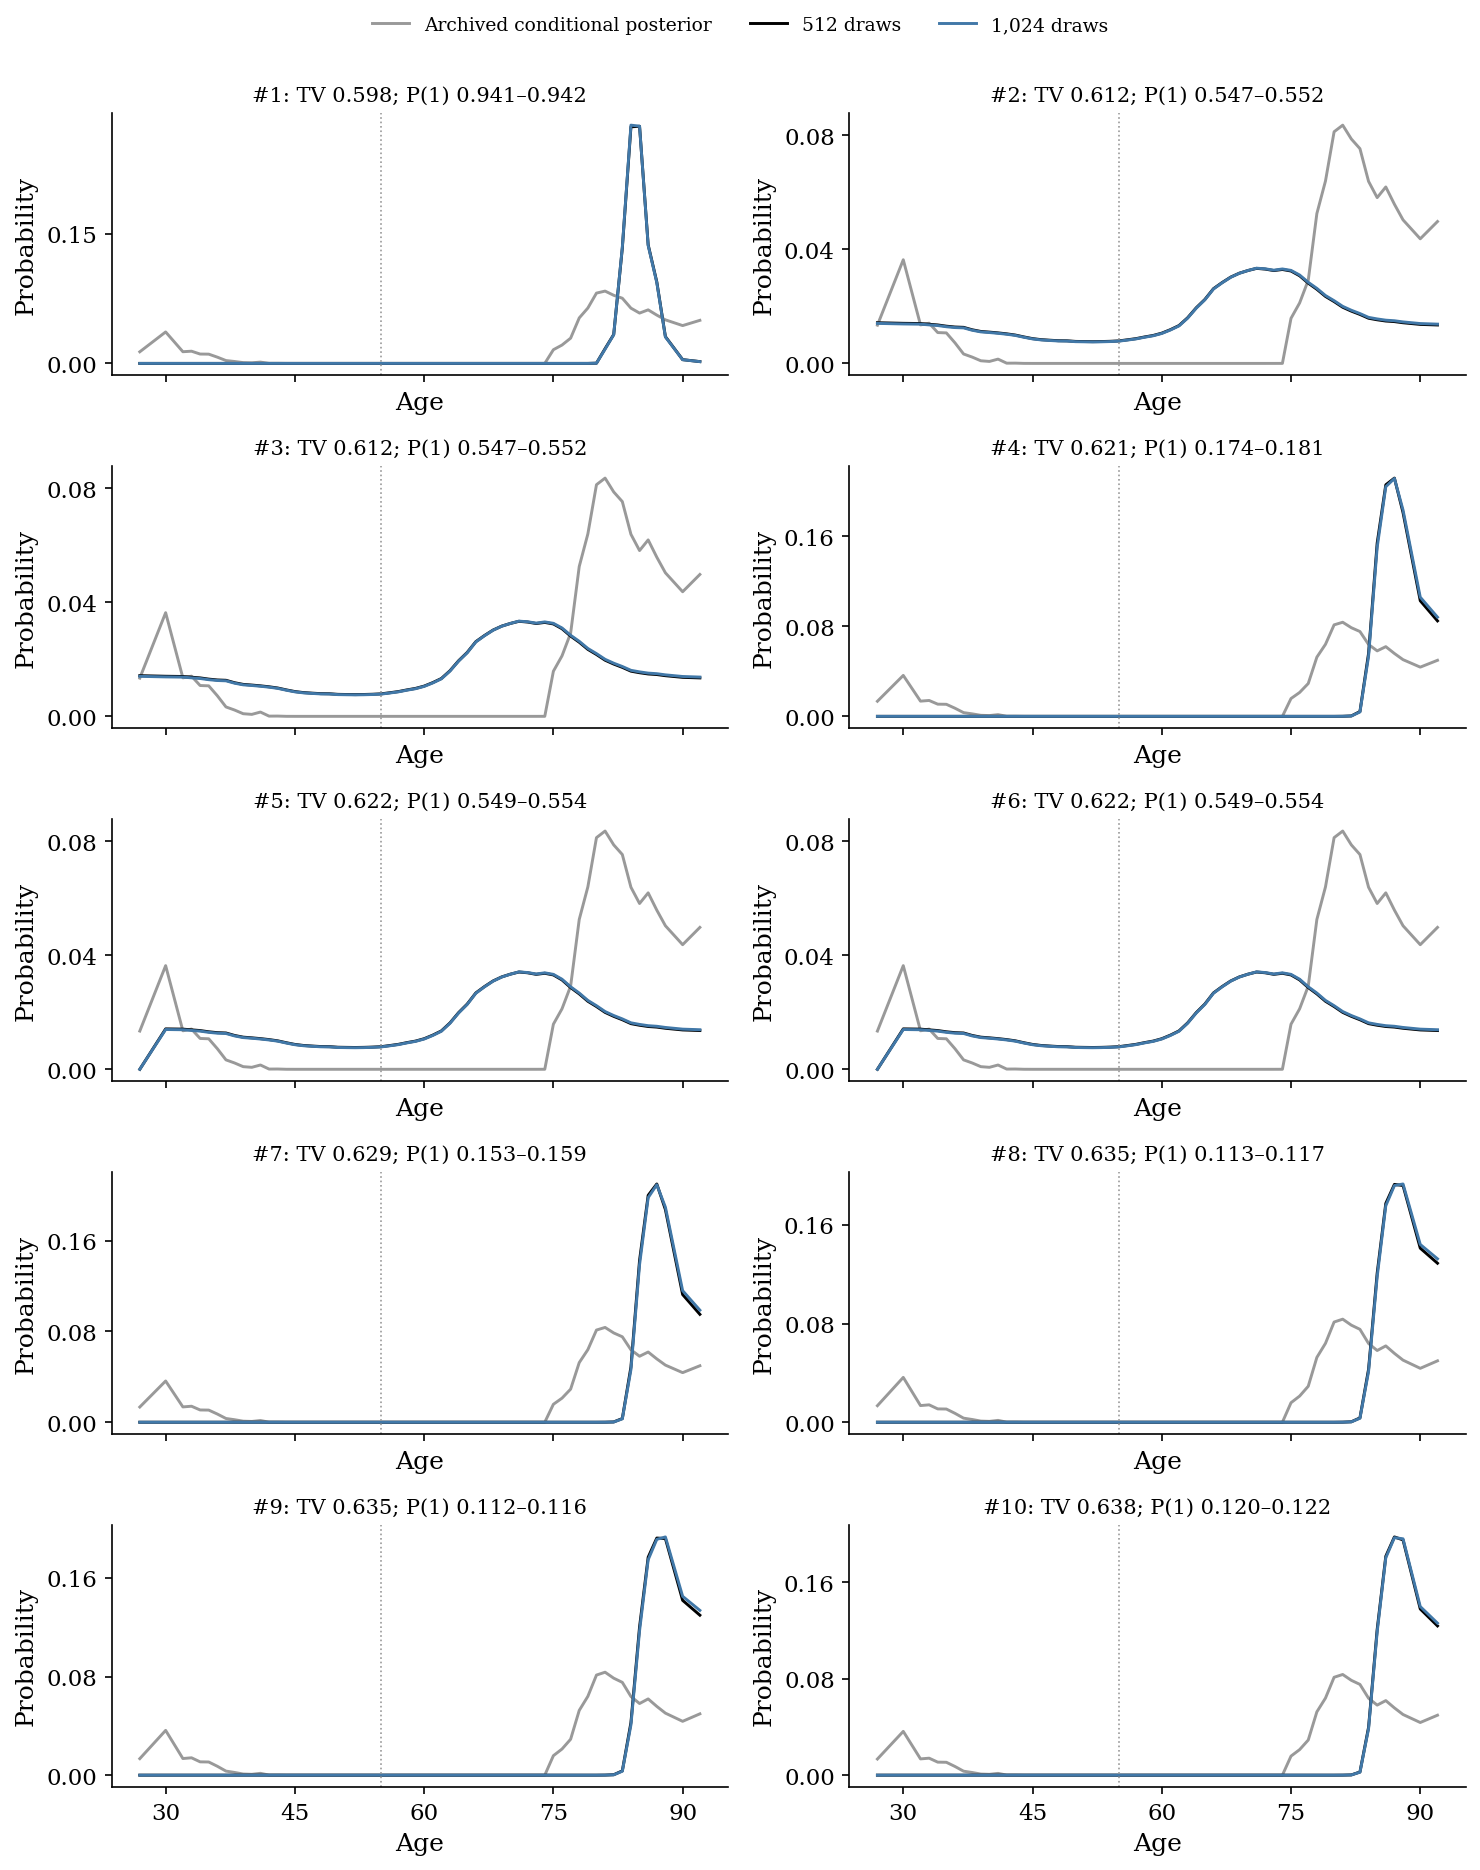

Overall #1: matched_logistic, fista, 100 fit updates; Delta=1, rho updates=1, initial scale=1.0; pilot age=67; P(1)=0.9406–0.9422; mean TV=0.5976; relative moment residual=0.4498.


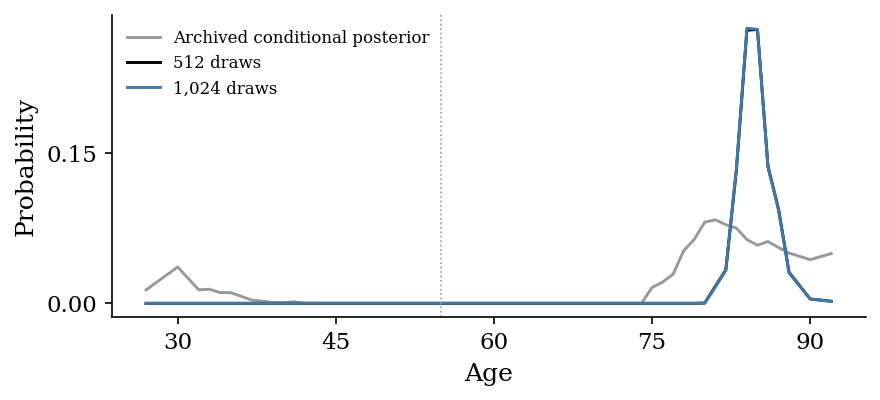

Overall #2: matched_logistic, fista, 1 fit updates; Delta=1, rho updates=20, initial scale=1.0; pilot age=67; P(1)=0.5469–0.5523; mean TV=0.6122; relative moment residual=0.753.


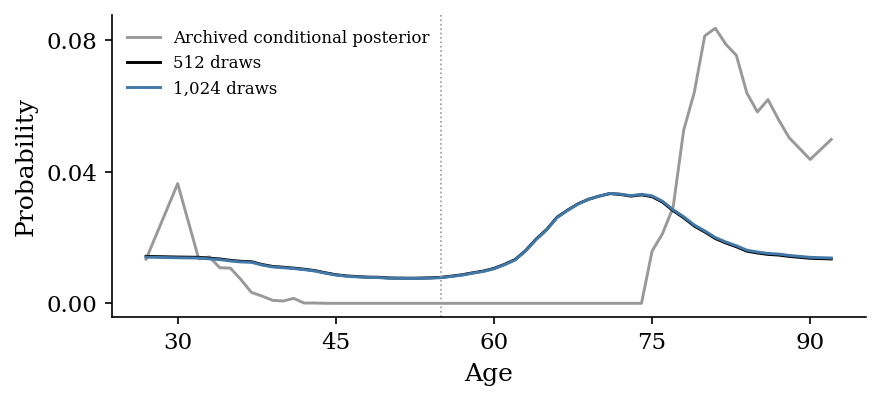

Overall #3: matched_logistic, gd, 1 fit updates; Delta=1, rho updates=20, initial scale=1.0; pilot age=67; P(1)=0.5469–0.5523; mean TV=0.6122; relative moment residual=0.753.


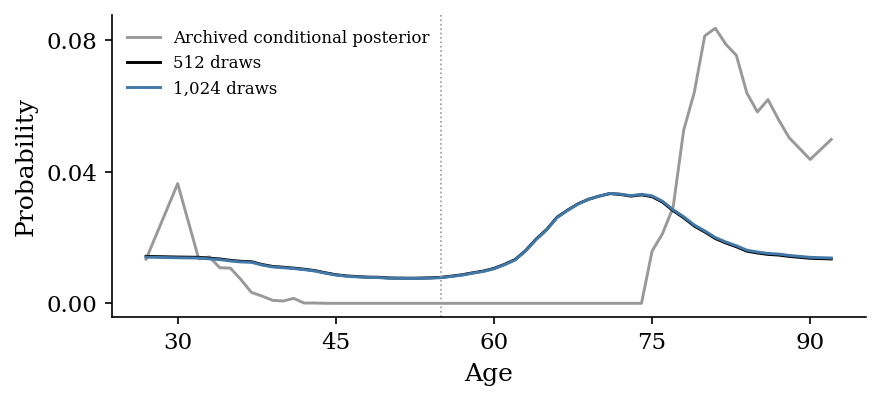

Overall #4: LS_auxiliary, fista, 100 fit updates; Delta=2, rho updates=-1, initial scale=1.0; pilot age=67; P(1)=0.1742–0.181; mean TV=0.6213; relative moment residual=0.00698.


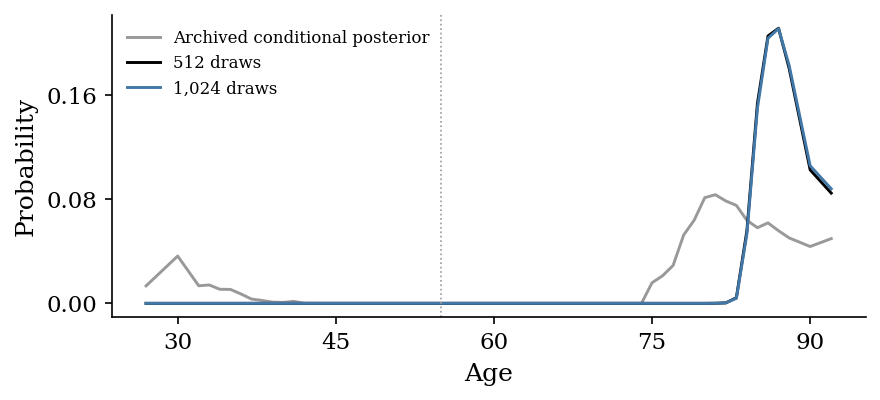

Overall #5: matched_logistic, fista, 1 fit updates; Delta=2, rho updates=20, initial scale=1.0; pilot age=67; P(1)=0.5492–0.5544; mean TV=0.6222; relative moment residual=0.7734.


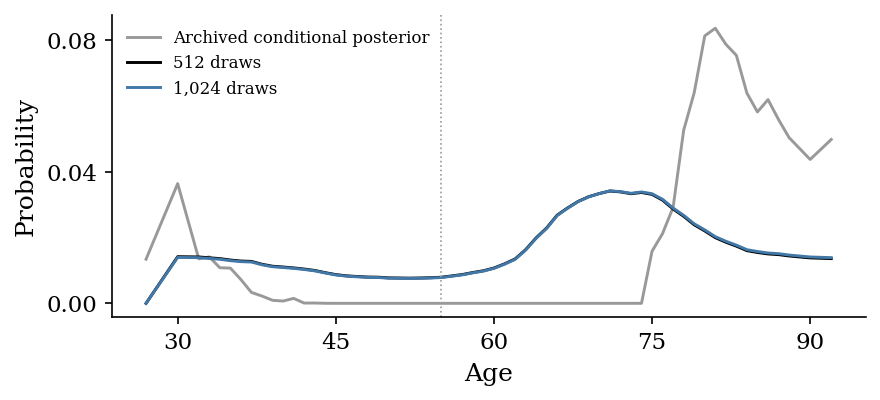

Overall #6: matched_logistic, gd, 1 fit updates; Delta=2, rho updates=20, initial scale=1.0; pilot age=67; P(1)=0.5492–0.5544; mean TV=0.6222; relative moment residual=0.7734.


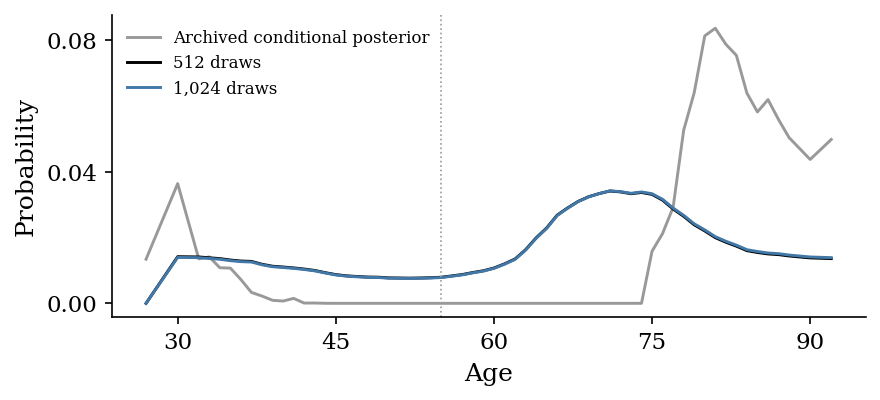

Overall #7: LS_auxiliary, fista, 100 fit updates; Delta=1, rho updates=-1, initial scale=1.0; pilot age=67; P(1)=0.1531–0.1592; mean TV=0.6294; relative moment residual=0.006608.


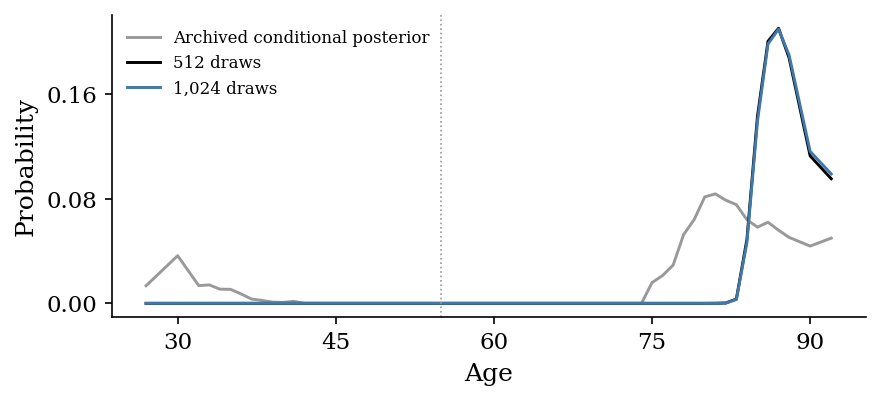

Overall #8: LS_auxiliary, fista, 100 fit updates; Delta=2, rho updates=20, initial scale=1.0; pilot age=67; P(1)=0.1132–0.1167; mean TV=0.6345; relative moment residual=0.01003.


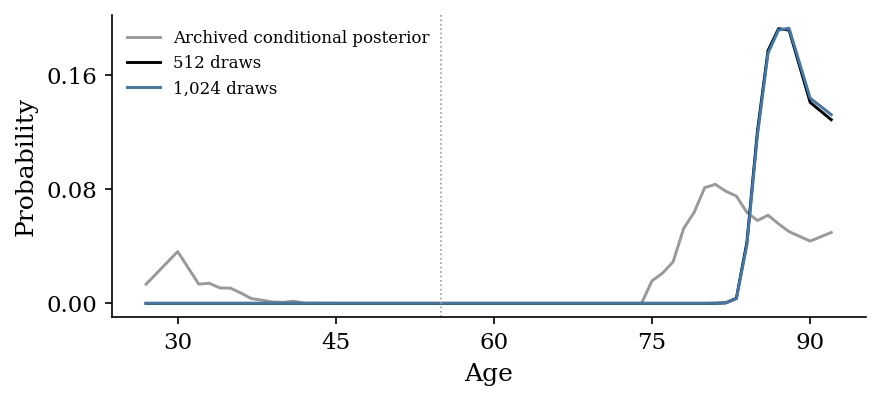

Overall #9: LS_auxiliary, fista, 100 fit updates; Delta=2, rho updates=30, initial scale=1.0; pilot age=67; P(1)=0.1121–0.1158; mean TV=0.6348; relative moment residual=0.009721.


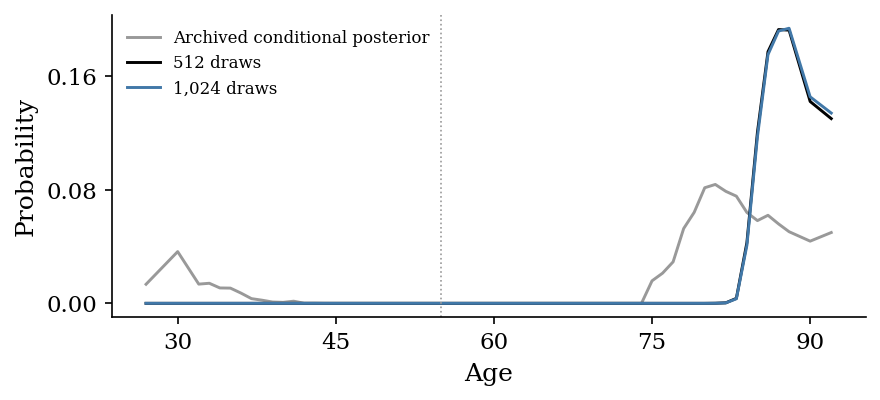

Overall #10: LS_auxiliary, fista, 100 fit updates; Delta=2, rho updates=10, initial scale=1.0; pilot age=67; P(1)=0.1199–0.1223; mean TV=0.6384; relative moment residual=0.01085.


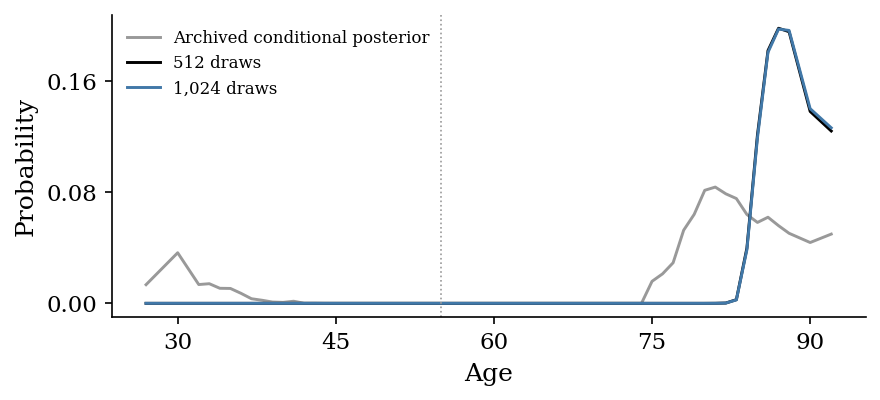

Matched logistic/logistic


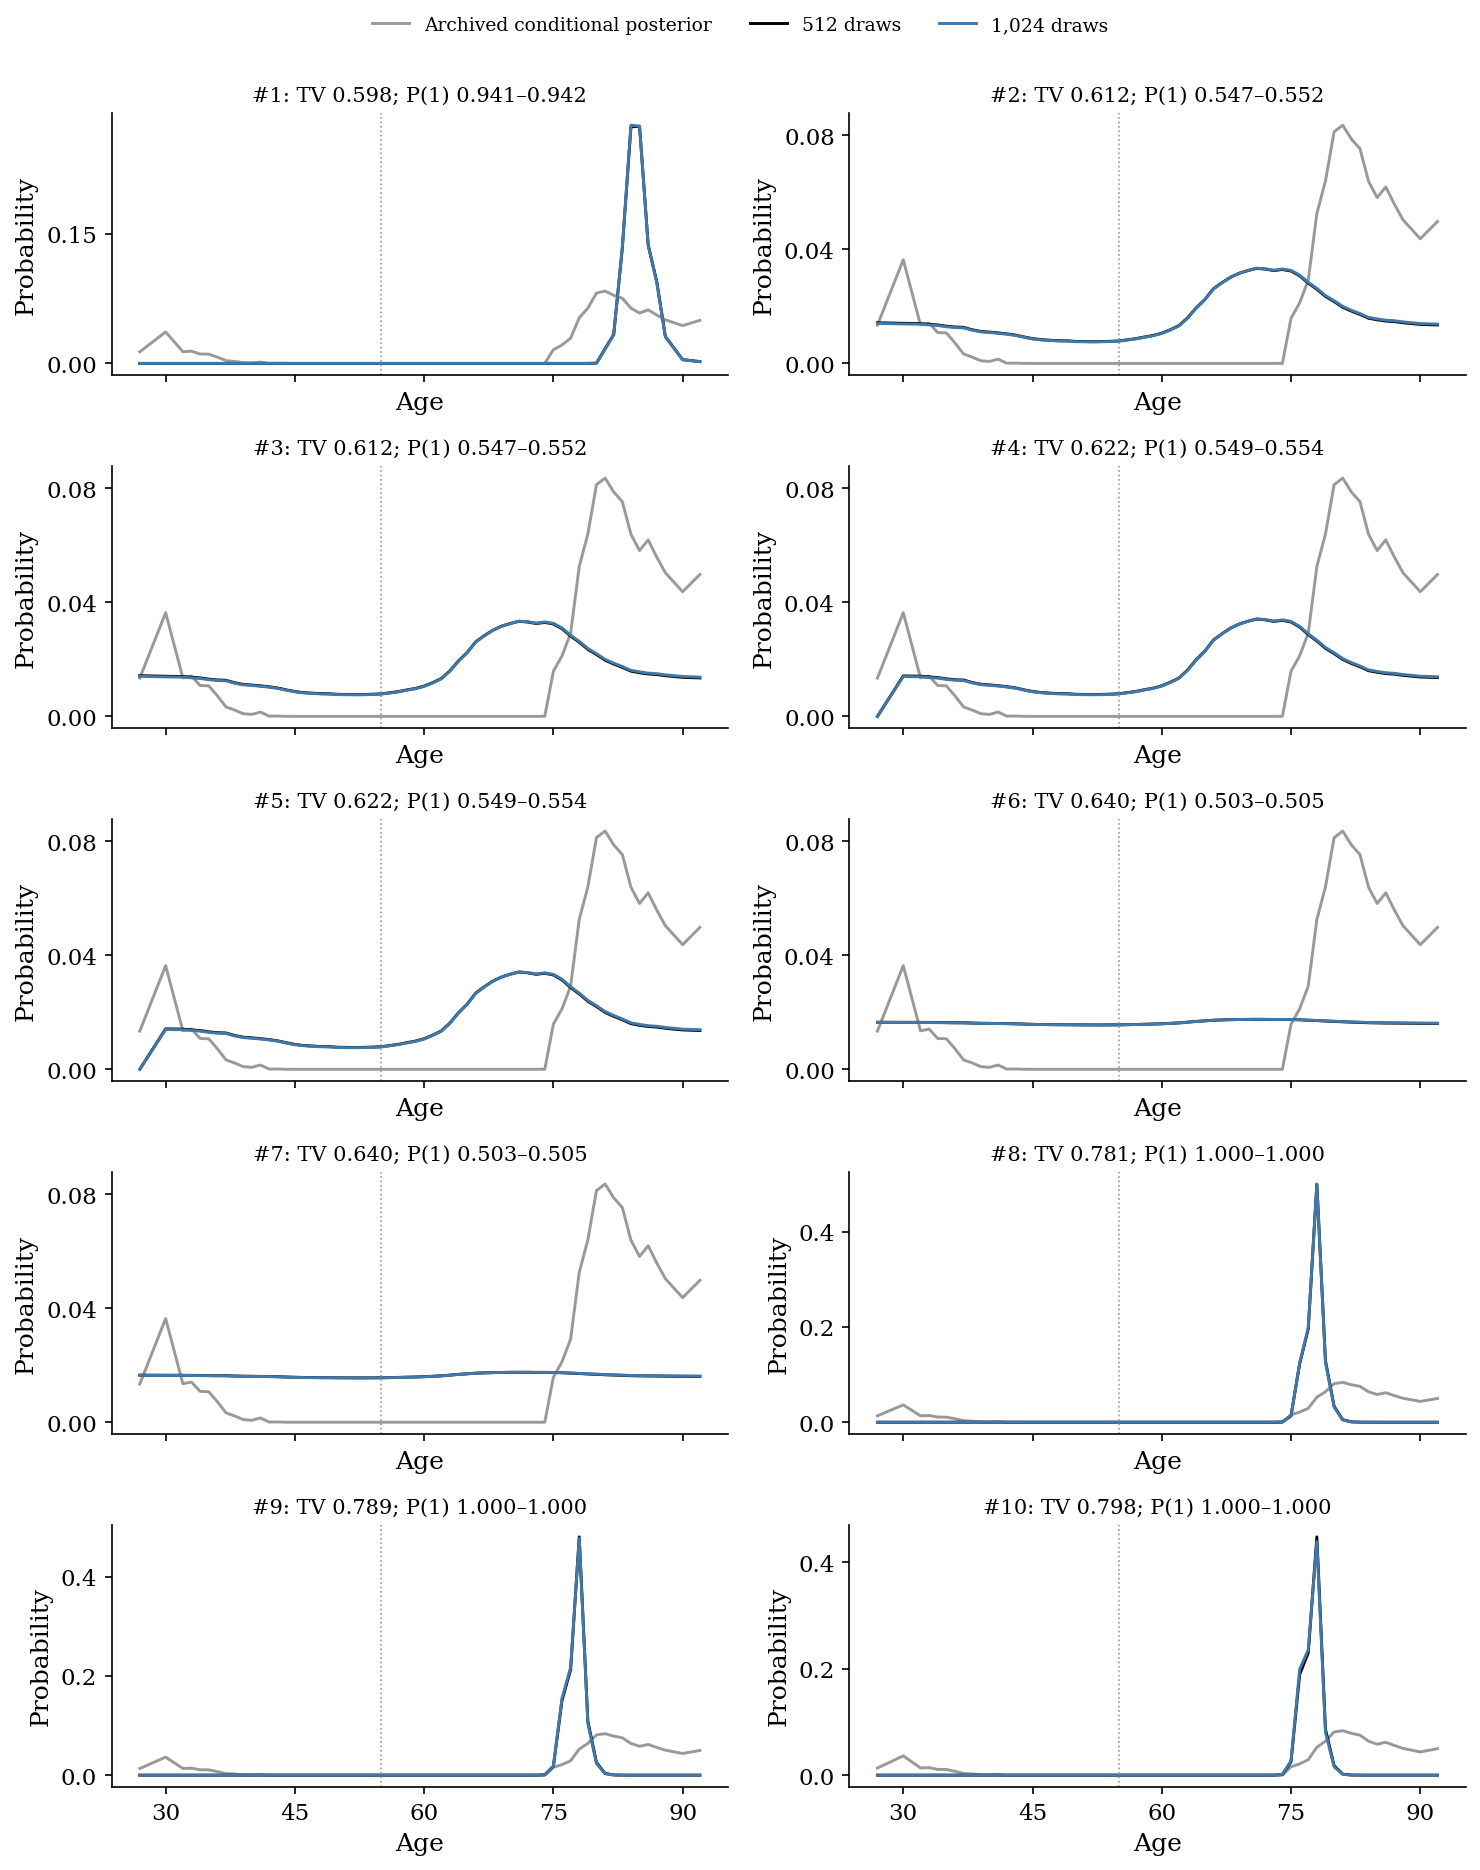

Matched logistic/logistic #1: matched_logistic, fista, 100 fit updates; Delta=1, rho updates=1, initial scale=1.0; pilot age=67; P(1)=0.9406–0.9422; mean TV=0.5976; relative moment residual=0.4498.


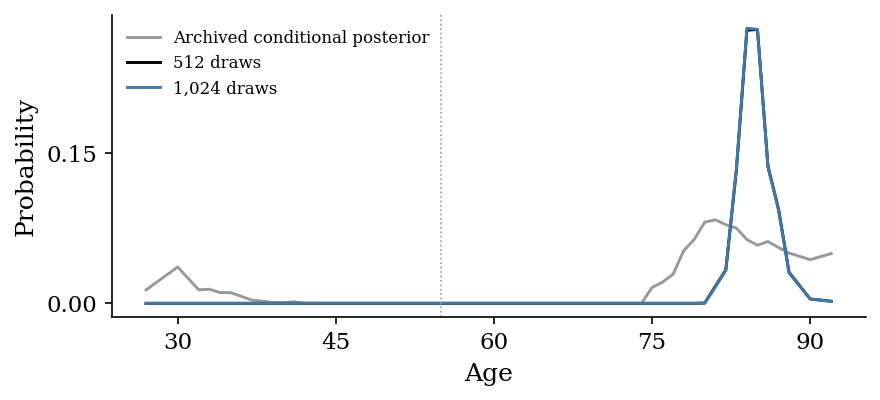

Matched logistic/logistic #2: matched_logistic, fista, 1 fit updates; Delta=1, rho updates=20, initial scale=1.0; pilot age=67; P(1)=0.5469–0.5523; mean TV=0.6122; relative moment residual=0.753.


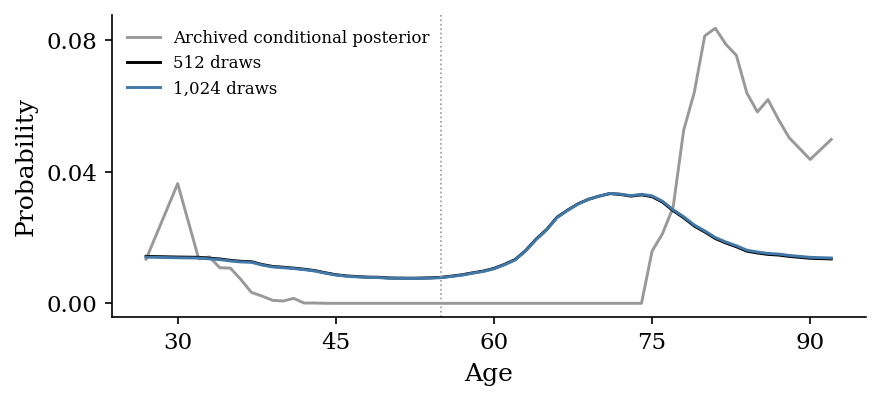

Matched logistic/logistic #3: matched_logistic, gd, 1 fit updates; Delta=1, rho updates=20, initial scale=1.0; pilot age=67; P(1)=0.5469–0.5523; mean TV=0.6122; relative moment residual=0.753.


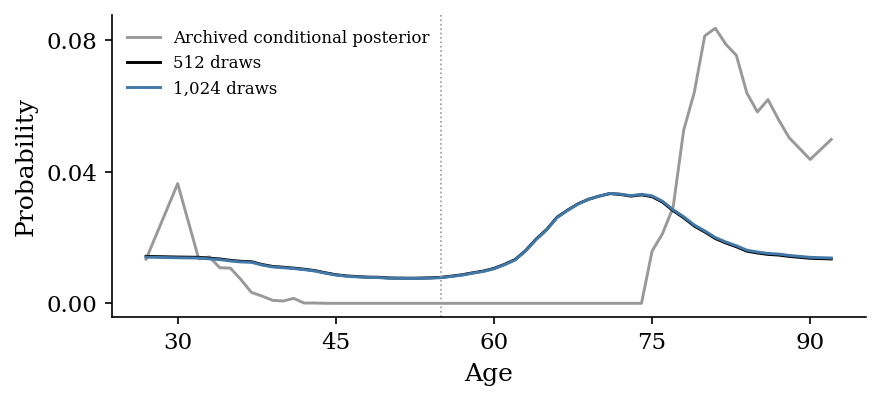

Matched logistic/logistic #4: matched_logistic, fista, 1 fit updates; Delta=2, rho updates=20, initial scale=1.0; pilot age=67; P(1)=0.5492–0.5544; mean TV=0.6222; relative moment residual=0.7734.


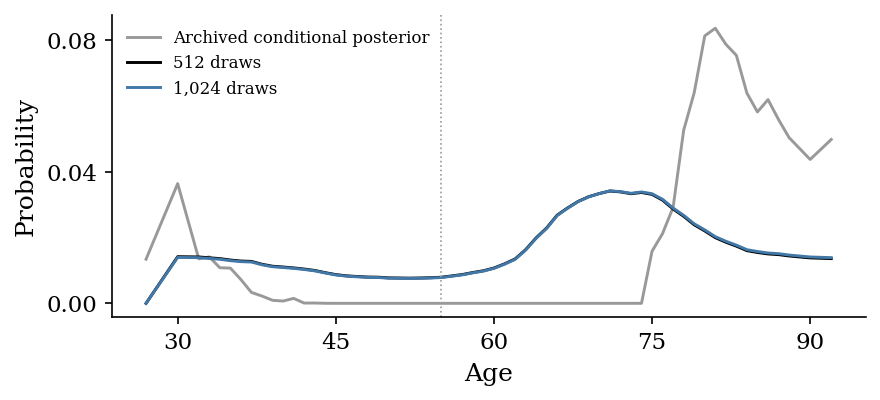

Matched logistic/logistic #5: matched_logistic, gd, 1 fit updates; Delta=2, rho updates=20, initial scale=1.0; pilot age=67; P(1)=0.5492–0.5544; mean TV=0.6222; relative moment residual=0.7734.


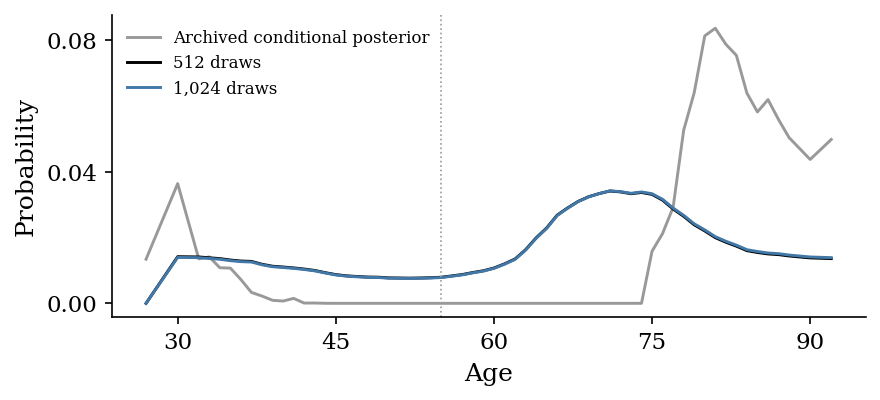

Matched logistic/logistic #6: matched_logistic, fista, 1 fit updates; Delta=1, rho updates=30, initial scale=1.0; pilot age=67; P(1)=0.5034–0.5053; mean TV=0.6402; relative moment residual=0.7457.


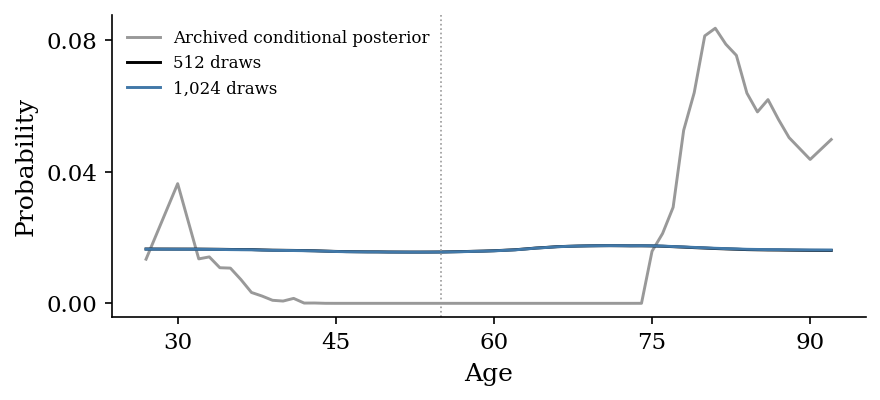

Matched logistic/logistic #7: matched_logistic, gd, 1 fit updates; Delta=1, rho updates=30, initial scale=1.0; pilot age=67; P(1)=0.5034–0.5053; mean TV=0.6402; relative moment residual=0.7457.


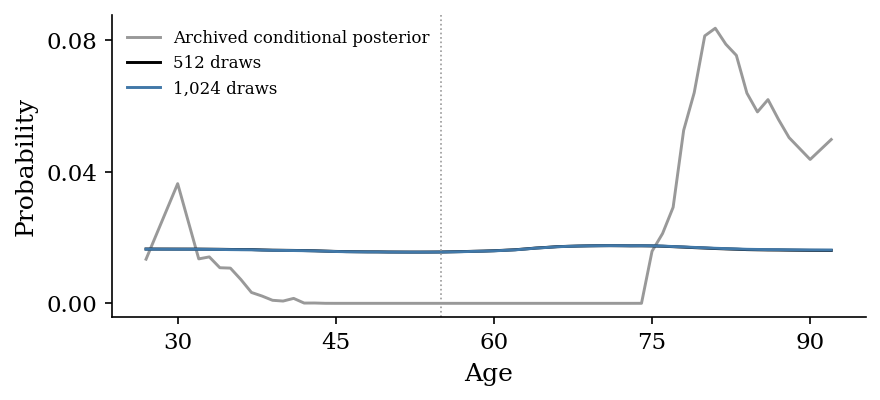

Matched logistic/logistic #8: matched_logistic, fista, 100 fit updates; Delta=1, rho updates=3, initial scale=1.0; pilot age=67; P(1)=1–1; mean TV=0.781; relative moment residual=0.2099.


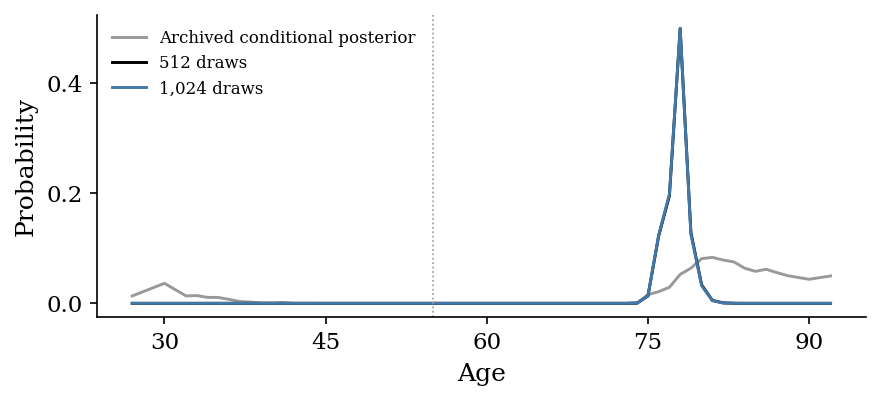

Matched logistic/logistic #9: matched_logistic, fista, 100 fit updates; Delta=2, rho updates=3, initial scale=1.0; pilot age=67; P(1)=1–1; mean TV=0.789; relative moment residual=0.2098.


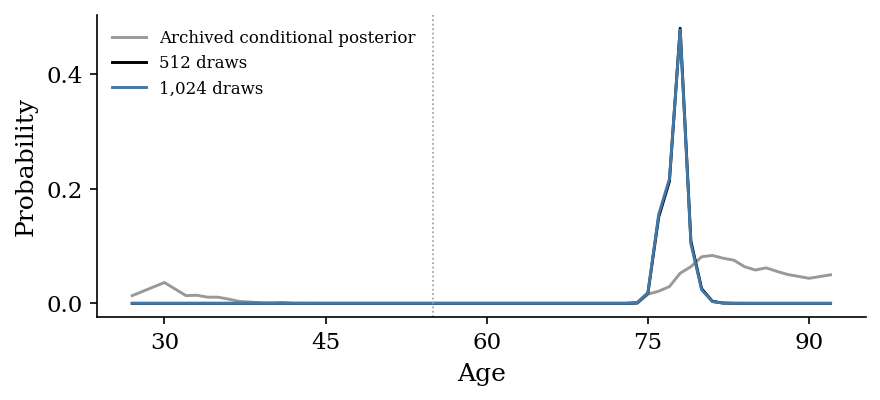

Matched logistic/logistic #10: matched_logistic, fista, 100 fit updates; Delta=5, rho updates=3, initial scale=1.0; pilot age=67; P(1)=1–1; mean TV=0.7985; relative moment residual=0.2096.


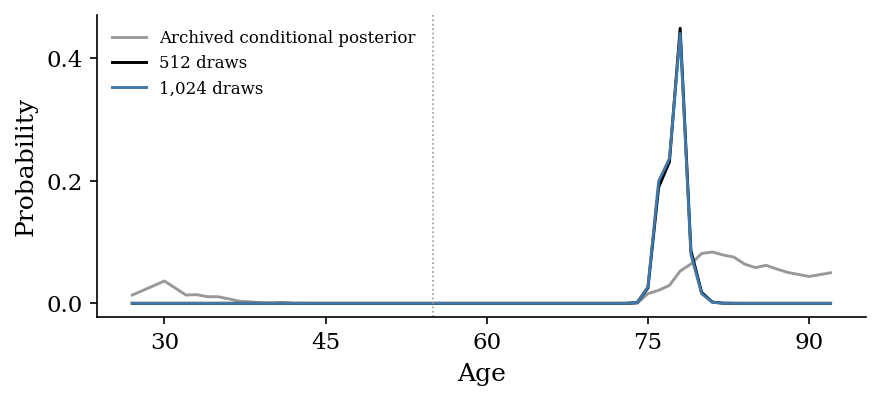

In [3]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
plt.rcParams.update({'font.family':'serif','mathtext.fontset':'cm','font.size':11,
    'axes.labelsize':12,'figure.dpi':150,'axes.spines.top':False,'axes.spines.right':False})
reference=reference_distribution();a=np.array(sorted(reference));p=np.array([reference[x] for x in a])
def draw(ax,row):
    ax.plot(a,p,color='0.6',lw=1.4,label='Archived conditional posterior')
    for tag,color,label in [('q9_seed42','black','512 draws'),('q10_seed123','#4178a8','1,024 draws')]:
        rec=pickle.load((root/(row.case+'__'+row.posterior_fit+'__'+tag+'.pkl')).open('rb'))
        mapping=dict(zip(rec['ages'],rec['conditional']))
        ax.plot(a,[mapping.get(x,0.) for x in a],color=color,lw=1.4,label=label)
    ax.axvline(55,color='0.6',ls=':',lw=.8);ax.set_xlabel('Age');ax.set_ylabel('Probability')
    ax.xaxis.set_major_locator(MaxNLocator(5,integer=True));ax.yaxis.set_major_locator(MaxNLocator(3))
for label,table in [('Overall',ranked.head(10)),('Matched logistic/logistic',ranked[ranked.group=='matched_logistic'].head(10))]:
    print(label)
    fig,axes=plt.subplots(5,2,figsize=(10,12.5),sharex=True)
    for i,(ax,row) in enumerate(zip(axes.flat,table.itertuples()),1):
        draw(ax,row);ax.set_title(f'#{i}: TV {row.mean_TV:.3f}; P(1) {row.P1_min:.3f}–{row.P1_max:.3f}',fontsize=10)
    for ax in list(axes.flat)[len(table):]:ax.set_visible(False)
    handles,labels=axes[0,0].get_legend_handles_labels()
    fig.legend(handles,labels,loc='upper center',ncol=3,frameon=False,fontsize=9)
    fig.tight_layout(rect=(0,0,1,.97));plt.show()
    for i,row in enumerate(table.itertuples(),1):
        print(f'{label} #{i}: {row.group}, {row.method}, {row.fit_budget} fit updates; '
              f'Delta={row.Delta}, rho updates={row.rho_updates}, initial scale={row.initial_scale}; '
              f'pilot age={row.pilot_age:g}; P(1)={row.P1_min:.4g}–{row.P1_max:.4g}; '
              f'mean TV={row.mean_TV:.4g}; relative moment residual={row.relative_moment_residual:.4g}.')
        fig,ax=plt.subplots(figsize=(6,2.8));draw(ax,row);ax.legend(frameon=False,fontsize=8)
        fig.tight_layout();plt.show()


All primary results: shape/probability trade-off, not a selection threshold


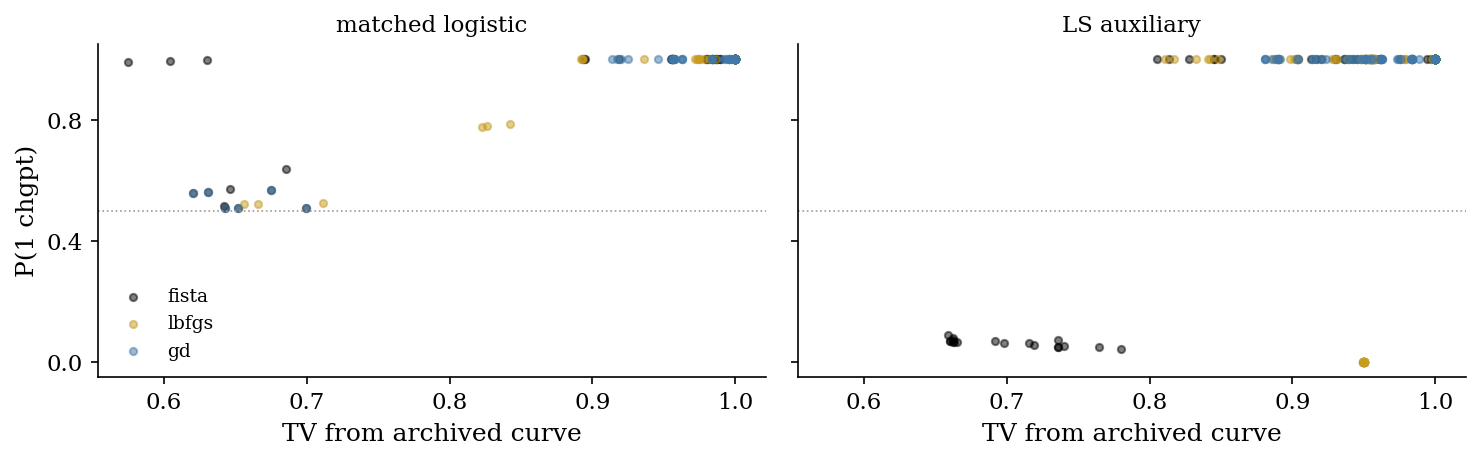

All fits have matched intercept=True; no explicit fitting penalties.
Numerical checks assess integration sensitivity, not independent-data validation.


In [4]:
print('All primary results: shape/probability trade-off, not a selection threshold')
fig,axes=plt.subplots(1,2,figsize=(10,3.2),sharex=True,sharey=True)
for ax,group in zip(axes,('matched_logistic','LS_auxiliary')):
    data=summary[summary.group==group]
    for method,color in [('fista','black'),('lbfgs','#c69c22'),('gd','#4178a8')]:
        sub=data[data.method==method];ax.scatter(sub.TV_to_reference,sub.P_1,s=12,alpha=.5,color=color,label=method)
    ax.axhline(.5,color='0.6',ls=':',lw=.8);ax.set_xlabel('TV from archived curve')
    ax.set_title(group.replace('_',' '),fontsize=11);ax.yaxis.set_major_locator(MaxNLocator(3))
axes[0].set_ylabel('P(1 chgpt)');axes[0].legend(frameon=False,fontsize=9)
fig.tight_layout();plt.show()
print('All fits have matched intercept=True; no explicit fitting penalties.')
print('Numerical checks assess integration sensitivity, not independent-data validation.')
